# Unconstrained Optimality Conditions



In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import linalg
from scipy.optimize import root

import sys

if "google.colab" in sys.modules:
    !wget "https://raw.githubusercontent.com/ndcbe/optimization/main/notebooks/helper.py"

else:
    sys.path.insert(0, "../")

import helper
from helper import set_plotting_style

set_plotting_style()

[Handout for Theorems 2.17 and 2.18 from Biegler (2010)](../../handouts/Theorem_proof_activity.pdf)

## Local and Global Solutions

## Necessary Conditions for Optimality

## Sufficient Conditions for Optimality

## Definitions and geometric proof guide

### Quantified minimizer definitions
For $f:\mathbb R^n\to\mathbb R$, let $B(\mathbf x^*,r)=\{\mathbf x:\|\mathbf x-\mathbf x^*\|<r\}$ with $r>0$.
A global minimizer satisfies $f(\mathbf x^*)\le f(\mathbf x)$ for every $\mathbf x\in\mathbb R^n$.
A local minimizer satisfies this inequality for every $\mathbf x\in B(\mathbf x^*,r)$ for some $r>0$.
Strict local minimality requires $f(\mathbf x^*)<f(\mathbf x)$ for every other point in that ball.
Isolation means that $\mathbf x^*$ is the only **local minimizer** in some ball.

![Four marked points, including a local maximum](../../media/figures/uo-minimizer-kinds.png)

### Isolated implies strict
Let $\mathbf x^*$ be a local minimizer isolated among local minimizers. Choose a radius $r$ for local minimality and a radius $R$ for isolation. If strictness fails, every sufficiently small neighborhood contains a distinct $\mathbf y$ with $f(\mathbf y)=f(\mathbf x^*)$; choose it inside both balls. Choose $0<\rho<r-\|\mathbf y-\mathbf x^*\|$. Every $\mathbf z\in B(\mathbf y,\rho)$ belongs to $B(\mathbf x^*,r)$ by the triangle inequality, and therefore $f(\mathbf z)\ge f(\mathbf x^*)=f(\mathbf y)$. This makes $\mathbf y$ a second local minimizer inside the isolating ball, a contradiction. The converse fails in the oscillatory example below.

![A smaller ball around an equal-value point inside the minimizing ball](../../media/figures/uo-nested-balls.png)

### Infimum and existence
For nonempty $A\subset\mathbb R$ bounded below, $m=\inf A$ means $m\le a$ for all $a\in A$, and for each $\epsilon>0$ there is $a\in A$ with $a<m+\epsilon$. The second condition rules out a larger lower bound. If $A$ is unbounded below, $\inf A=-\infty$. A minimum is attained; for an objective on $S$, apply this definition to $A=f(S)$.
For $f(x)=e^x$ on $\mathbb R$, $\inf f(\mathbb R)=0$ because $f(x)>0$ and $f(x)\to0$ as $x\to-\infty$, but no point attains it.

Weierstrass says that a continuous function on a nonempty compact set attains its minimum and maximum (see the Real Analysis Review lecture). If a continuous objective has a bounded sublevel set $S=\{\mathbf x:f(\mathbf x)\le f(\bar{\mathbf x})\}$, then $S$ is nonempty, closed, bounded and hence compact in $\mathbb R^n$. Its minimizer is global: all points outside $S$ have value larger than $f(\bar{\mathbf x})$. A coercive continuous objective satisfies this hypothesis because $f(\mathbf x)\to\infty$ as $\|\mathbf x\|\to\infty$.

### Convexity certificates
Convexity on a convex domain means $f(\theta\mathbf x_a+(1-\theta)\mathbf x_b)\le\theta f(\mathbf x_a)+(1-\theta)f(\mathbf x_b)$ for all points and $0<\theta<1$. Strict convexity replaces $\le$ by $<$ for distinct points. Stationarity means $\nabla f(\mathbf x^*)=\mathbf0$.

If $\mathbf x_a$ is local but not global, choose $\mathbf x_b$ with $f(\mathbf x_b)<f(\mathbf x_a)$; $\mathbf x_b$ need not be local. For $\bar{\mathbf x}=\theta\mathbf x_a+(1-\theta)\mathbf x_b$, the distance $\|\bar{\mathbf x}-\mathbf x_a\|=(1-\theta)\|\mathbf x_b-\mathbf x_a\|$ is smaller than the local radius for $\theta<1$ sufficiently close to one. Convexity then gives $f(\bar{\mathbf x})\le f(\mathbf x_a)+(1-\theta)[f(\mathbf x_b)-f(\mathbf x_a)]<f(\mathbf x_a)$, contradicting local minimality.

![Chord contradiction and the actual local ball](../../media/figures/uo-convex-contradiction.png)

Two distinct global minimizers of a strictly convex function cannot tie at $m$: their midpoint has value less than $m$. This proves uniqueness **if a minimizer exists**. Convex differentiable functions also obey the tangent inequality $f(\mathbf x^*+\mathbf p)\ge f(\mathbf x^*)+\nabla f(\mathbf x^*)^T\mathbf p$. At stationarity the last term is zero, proving global optimality.

![Midpoint and supporting tangent mechanisms](../../media/figures/uo-convex-certificates.png)

### Exact identities and necessary conditions
Assume $f\in C^2$ on a neighborhood of the segment. Set $\psi(t)=f(\mathbf x+t\mathbf p)$. The scalar mean-value theorem gives some $\tau_1\in(0,1)$ with
$f(\mathbf x+\mathbf p)=f(\mathbf x)+\nabla f(\mathbf x+\tau_1\mathbf p)^T\mathbf p$.
Scalar Taylor's theorem gives some $\tau_2\in(0,1)$ with
$f(\mathbf x+\mathbf p)=f(\mathbf x)+\nabla f(\mathbf x)^T\mathbf p+\tfrac12\mathbf p^T\nabla^2 f(\mathbf x+\tau_2\mathbf p)\mathbf p$.
The intermediate points can differ. The fundamental theorem of calculus applied componentwise gives the vector identity
$\nabla f(\mathbf x+\mathbf p)-\nabla f(\mathbf x)=\int_0^1\nabla^2 f(\mathbf x+t\mathbf p)\mathbf p\,dt$; it does not require a common vector mean-value point.

![The objective and local Taylor models](../../media/figures/uo-taylor-model.png)

At a local minimum, if $\mathbf g=\nabla f(\mathbf x^*)\ne0$, choose $\mathbf p=-\mathbf g$. The **scalar** slope $\psi'(s)=\nabla f(\mathbf x^*+s\mathbf p)^T\mathbf p$ is continuous and starts at $-\|\mathbf g\|^2<0$. It remains negative for all sufficiently small positive $s$. The scalar mean-value theorem gives $\psi(s)-\psi(0)=s\psi'(\tau)<0$ with $\tau\in(0,s)$; choose $s\|\mathbf p\|<r$ to remain inside the local minimizing ball. This contradiction proves stationarity.

If the Hessian has a direction with $\mathbf p^T\nabla^2 f(\mathbf x^*)\mathbf p<0$, continuity keeps that scalar curvature negative along a short segment. At stationarity the linear Taylor term vanishes, leaving a negative quadratic remainder and the same contradiction. Thus the Hessian must be positive semidefinite. A zero curvature direction gives no such sign guarantee: $x^4,-x^4,x^3$ and the constant zero function all have zero gradient and Hessian at zero, but different classifications.

![Positive steps descend in the first panel; negative curvature in the second](../../media/figures/uo-descent-proof.png)

### Sufficient conditions: strictness and isolation
Suppose $\nabla f(\mathbf x^*)=0$ and $\nabla^2 f(\mathbf x^*)\succ0$. Continuity keeps the Hessian positive definite in a sufficiently small ball (the smallest eigenvalue remains positive). For every nonzero displacement staying in that ball, the second Taylor identity gives a strictly positive objective change. This proves strict local minimality.

If another local minimizer $\mathbf y$ lay in that ball, its gradient would also be zero. With $\mathbf p=\mathbf y-\mathbf x^*$, convexity of the ball keeps the whole segment inside it. Multiplying the gradient integral identity by $\mathbf p^T$ gives $0=\int_0^1\mathbf p^T\nabla^2 f(\mathbf x^*+t\mathbf p)\mathbf p\,dt>0$, a contradiction. This proves isolation. The certificate is local and gives no comparison with distant basins.

![Positive change in objective and curvature along the full segment](../../media/figures/uo-positive-curvature.png)

Sources: Biegler (2010), Chapter 2, Def. 2.15 and Thms. 2.14, 2.16–2.18, pp. 27–30, with errata; Nocedal and Wright (2006), §2.1, pp. 12–17.


## Example 2.19 in Biegler (2010)

**Main Idea**: Use the necessary and sufficient conditions to classify a candidate solution in the following example.

\begin{align}
\min f(\mathbf{x}) &= \alpha \exp(-\beta) \\
u &= x_1 - 0.8, \\
v &= x_2 - (a_1 + a_2u^2(1-u)^{\frac{1}{2}} - a_3u), \\
\alpha &= -b_1 + b_2u^2(1+u)^{\frac{1}{2}} + b_3u, \\
\beta &= c_1 v^2(1 - c_2v) / (1 + c_3u^2) 
\end{align}

with
\begin{align}
\mathbf{a}^T &= [0.3, 0.6, 0.2], \nonumber \\
\mathbf{b}^T &= [5, 26, 3], \nonumber \\
\mathbf{c}^T &= [40, 1, 10]. \nonumber
\end{align}

Biegler reports the rounded candidate $\mathbf{x}^* = [0.7395, 0.3144]$ with $f(\mathbf{x}^*) = -5.0893$.

At the underlying stationary point, the book reports the Hessian
\begin{align}
\nabla^2 f(\mathbf{x}^*) &= \begin{bmatrix} 77.012 & 108.334 \\ 108.334 & 392.767 \end{bmatrix},
\end{align}
which has eigenvalues $\lambda = 43.417$ and $\lambda = 426.362$.

The square roots require $-1\le u\le1$. The model is smooth in the interior $|u|<1$. The printed candidate is rounded: its computed gradient is small but not zero. We refine it below before comparing derivative values; the figure window is not the full domain.

### The Test Function

In [2]:
## Define Python function
def my_f(x, verbose=False):
    """Evaluate function given above at point x

    Inputs:
        x - vector with 2 elements

    Outputs:
        f - function value (scalar)
    """
    # Constants
    a = np.array([0.3, 0.6, 0.2])
    b = np.array([5, 26, 3])
    c = np.array([40, 1, 10])

    # Intermediates. Recall Python indices start at 0
    u = x[0] - 0.8
    s = np.sqrt(1 - u)
    s2 = np.sqrt(1 + u)
    v = x[1] - (a[0] + a[1] * u**2 * s - a[2] * u)
    alpha = (
        -b[0] + b[1] * u**2 * s2 + b[2] * u
    )  # September 5, 2018: changed 's' to 's2'
    beta = c[0] * v**2 * (1 - c[1] * v) / (1 + c[2] * u**2)
    f = alpha * np.exp(-beta)

    if verbose:
        print("##### my_f at x = ", x, "#####")
        print("u = ", u)
        print("sqrt(1-u) = ", s)
        print("sqrt(1+u) = ", s2)
        print("v = ", v)
        print("alpha = ", alpha)
        print("beta = ", beta)
        print("f(x) = ", f)
        print("##### Done. #####\n")

    return f

In [3]:
## Define candidate point and check against value reported in book
xtest = np.array([0.7395, 0.3144])
ftest = my_f(xtest)
my_f(xtest, verbose=True)

## Evaluate a two-dimensional grid
x1 = np.arange(0.0, 1.1, 0.05)
x2 = np.arange(0.0, 1.0, 0.05)

# Create a matrix of all points to sample
X1, X2 = np.meshgrid(x1, x2)
n1 = len(x1)
n2 = len(x2)

# Notice the order. This was wrong in quadratic.ipynb and has been corrected in quadratic_update.ipynb
F = np.zeros([n2, n1])

xtemp = np.zeros(2)

# Evaluate f(x) over grid
for i in range(0, n1):
    xtemp[0] = x1[i]
    for j in range(0, n2):
        xtemp[1] = x2[j]
        F[j, i] = my_f(xtemp)



##### my_f at x =  [0.7395 0.3144] #####
u =  -0.0605
sqrt(1-u) =  1.029805806936434
sqrt(1+u) =  0.9692780818733084
v =  3.839197709659681e-05
alpha =  -5.089257197421404
beta =  5.687377052495847e-08
f(x) =  -5.089256907976166
##### Done. #####



**Discussion:** The two-dimensional contour plot below shows one basin. A picture alone does not prove convexity or global optimality. Compare the local derivative test with the definitions above.

### Finite Difference Gradient and Hessian

We need to calculate $\nabla f(\mathbf{x})$ and $\nabla^2 f(\mathbf{x})$ to analyze a given point. Below are functions that implement a central finite difference. Another option is to analytically calculate the derivatives or use automatic differentiation.

In [4]:
## Gradient
def my_grad(x, verbose=True, eps=1e-6):
    """
    Calculate gradient of function my_f using central difference formula

    Inputs:
        x - point for which to evaluate gradient

    Outputs:
        grad - gradient (vector)

    Assumptions:
        1. my_f is defined
        2. input x has the correct number of elements for my_f
        3. my_f is continuous and differentiable
    """

    n = len(x)
    grad = np.zeros(n)

    if verbose:
        print("***** my_grad at x = ", x, "*****")

    for i in range(0, n):

        # Create vector of zeros except eps in position i
        e = np.zeros(n)
        e[i] = eps

        # Finite difference formula
        my_f_plus = my_f(x + e)
        my_f_minus = my_f(x - e)

        # Diagnostics
        if verbose:
            print("e[", i, "] = ", e)
            print("f(x + e[", i, "]) = ", my_f_plus)
            print("f(x - e[", i, "]) = ", my_f_minus)

        grad[i] = (my_f_plus - my_f_minus) / (2 * eps)

    if verbose:
        print("***** Done. ***** \n")

    return grad


grad = my_grad(xtest)
print(grad)

***** my_grad at x =  [0.7395 0.3144] *****
e[ 0 ] =  [1.e-06 0.e+00]
f(x + e[ 0 ]) =  -5.089256904035737
f(x - e[ 0 ]) =  -5.089256911839596
e[ 1 ] =  [0.e+00 1.e-06]
f(x + e[ 1 ]) =  -5.089256892701673
f(x - e[ 1 ]) =  -5.089256922857939
***** Done. ***** 

[0.00390193 0.01507813]


**Discussion**: According to the book, $\nabla f(\mathbf{x}_{test}) = \mathbf{0}$. Is the above answer reasonable?

**Note**: Before fixing the mistake in `my_f`, the gradient was `[-0.28182046  0.01506107]`. The version we discussed in class had the mistake in `my_f`.

In [5]:
## Hessian
def my_hes(x, eps=1e-4, grad_eps=1e-6):
    """
    Calculate Hessian of function my_f using central difference formula and my_grad

    Inputs:
        x - point for which to evaluate gradient

    Outputs:
        H - Hessian (matrix)

    Assumptions:
        1. my_f and my_grad are defined
        2. input x has the correct number of elements for my_f
        3. my_f is continuous and twice differentiable
        4. No mistakes in my_grad
    """

    n = len(x)
    H = np.zeros([n, n])

    for i in range(0, n):
        # Create vector of zeros except eps in position i
        e = np.zeros(n)
        e[i] = eps

        # Evaluate gradient twice
        grad_plus = my_grad(x + e, verbose=False, eps=grad_eps)
        grad_minus = my_grad(x - e, verbose=False, eps=grad_eps)

        # Notice we are building the Hessian by column (or row)
        H[:, i] = (grad_plus - grad_minus) / (2 * eps)

    """
    Note: This is not very efficient. You can probably think of several 
    performance improvements. We will learn more practical ways to approximate 
    the Hessian for optimization algorithms in the next few lectures.
    """

    return H


H = my_hes(xtest)
print(H)

[[ 76.99959337 108.341347  ]
 [108.34137365 392.71895957]]


**Primary Discussion**: How does this compare to the answer given in the book? Which elements are very close to the given answer? Which have greater error? Why does this make sense?

**Secondary Discussion**: What happens if you set `eps` to different values in `my_grad` and `my_hes`? Is `H` still symmetric?

Here the gradient difference step is $h=10^{-6}$ and the outer Hessian step is $k=10^{-4}$. Taking both extremely small can amplify subtraction error. The computed Hessian need not be exactly symmetric; report its asymmetry before using $(H+H^T)/2$ for a symmetric eigenvalue calculation. Compare several step sizes below.

### Analysis of Optimality Conditions

**Activity**
1. Calculate the eigenvalues of H.
2. Is $\mathbf{x}_{test}$ a
    * stationary point
    * local maximizer
    * strict global maximizer
    * global maximizer
    * local minimizer
    * strict local minimizer
    * global minimizer
    
Answer Yes, No, or Possibly for each bullet point.

In [6]:
### BEGIN SOLUTION
print(linalg.eigvals(H))
### END SOLUTION

[ 43.39771399+0.j 426.32083895+0.j]


### Refine the point and show the calculations

The book's eigenvalues above are supplied comparison data. The following calculation evaluates them independently. The separate eigenvalue activity retains its solution markers.

Central differences use the coordinate vector $\mathbf e_i$:

$$g_i(\mathbf x)\approx\frac{f(\mathbf x+h\mathbf e_i)-f(\mathbf x-h\mathbf e_i)}{2h},\qquad
H_{ij}(\mathbf x)\approx\frac{g_i(\mathbf x+k\mathbf e_j)-g_i(\mathbf x-k\mathbf e_j)}{2k}.$$

A root solve for the numerical gradient refines the candidate. Check the termination message and residual; a numerical solve is not a proof of exact stationarity.


In [7]:
# Refine using the same objective and finite-difference gradient defined above.
refinement = root(lambda x: my_grad(x, verbose=False), xtest, tol=1e-10)
xref = refinement.x
ref_residual = float(np.linalg.norm(my_grad(xref, verbose=False)))
if not refinement.success and ref_residual > 1e-7:
    raise RuntimeError(refinement.message)
raw_H = my_hes(xref)
sym_H = (raw_H + raw_H.T) / 2
values, vectors = np.linalg.eigh(sym_H)
if np.any(values <= 0):
    raise RuntimeError("The local quadratic ellipse requires positive eigenvalues")
delta_f = 0.25
semi_axes = np.sqrt(2 * delta_f / values)
print("Refinement:", refinement.message)
print("Residual norm:", ref_residual)
my_f(xref, verbose=True)
print("Hessian asymmetry norm:", np.linalg.norm(raw_H - raw_H.T))
print("Compare Hessian steps and eigenvalues:")
for k in [3e-4, 1e-4, 3e-5]:
    Hk = my_hes(xref, eps=k)
    print(k, np.linalg.eigvalsh((Hk + Hk.T) / 2))

# The complete grid and quadratic geometry are archived for the handout figure.
xx = np.linspace(0, 1.1, 151)
yy = np.linspace(0, 1.0, 151)
zz = np.array([[my_f(np.array([x,y])) for x in xx] for y in yy])
results = dict(x=xx.tolist(), y=yy.tolist(), objective=zz.tolist(),
    rounded=xtest.tolist(), refined=xref.tolist(), objective_refined=float(my_f(xref)),
    gradient_refined=my_grad(xref, verbose=False).tolist(),
    hessian=sym_H.tolist(), eigenvalues=values.tolist(), eigenvectors=vectors.tolist(),
    delta_f=delta_f, semi_axes=semi_axes.tolist())
helper.save_results("optimality-example-2-19", results,
    notebook="notebooks/6-dev/Optimality.ipynb", source_tag=None,
    source_cells=[("notebooks/6-dev/Optimality.ipynb", tag) for tag in
      ["results:uo-example-model", "results:uo-gradient", "results:uo-hessian", "results:uo-example-data"]],
    description="Full Biegler Example 2.19 objective and refined local quadratic ellipse", quiet=True)


Refinement: The solution converged.
Residual norm: 0.0
##### my_f at x =  [0.73950546 0.3143601 ] #####
u =  -0.060494538339870285
sqrt(1-u) =  1.029803155141734
sqrt(1+u) =  0.969280899254767
v =  5.669353875248362e-13
alpha =  -5.089257198124354
beta =  1.2402740014872362e-23
f(x) =  -5.089257198124354
##### Done. #####

Hessian asymmetry norm: 4.39625888431457e-05
Compare Hessian steps and eigenvalues:
0.0003 [ 43.41741485 426.3602212 ]
0.0001 [ 43.41742864 426.36146937]
3e-05 [ 43.41744101 426.36161168]


In [8]:
print("Central differences: h=1e-6 (gradient), k=1e-4 (Hessian)")
print(f"Rounded x=({xtest[0]:.4f}, {xtest[1]:.4f}), ||g||={np.linalg.norm(my_grad(xtest,False)):.3e}")
print(f"Refined x=({xref[0]:.8f}, {xref[1]:.8f}), f={my_f(xref):.8f}")
print(f"||g(refined)||={ref_residual:.3e}")
print(f"H rows: [{sym_H[0,0]:.3f}, {sym_H[0,1]:.3f}]; [{sym_H[1,0]:.3f}, {sym_H[1,1]:.3f}]")
print(f"Eigenvalues: {values[0]:.3f}, {values[1]:.3f}; semi-axes: {semi_axes[0]:.4f}, {semi_axes[1]:.4f}")


Central differences: h=1e-6 (gradient), k=1e-4 (Hessian)
Rounded x=(0.7395, 0.3144), ||g||=1.557e-02
Refined x=(0.73950546, 0.31436010), f=-5.08925720
||g(refined)||=0.000e+00
H rows: [77.012, 108.334]; [108.334, 392.767]
Eigenvalues: 43.417, 426.361; semi-axes: 0.1073, 0.0342


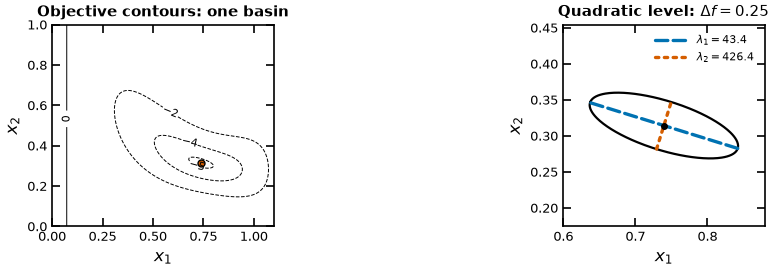

In [9]:
# One plotting cell serves the notebook, archive renderer, and printed handout.
fig, axes = plt.subplots(1,2,figsize=(10,2.7),layout='constrained')
x=np.asarray(results['x']); y=np.asarray(results['y']); z=np.asarray(results['objective'])
xr=np.asarray(results['refined']); Q=np.asarray(results['eigenvectors'])
radii=np.asarray(results['semi_axes']); lam=np.asarray(results['eigenvalues'])
cs=axes[0].contour(x,y,z,levels=[-5,-4,-2,0,2,5,10,15],colors='black',linewidths=.7)
axes[0].clabel(cs,fontsize=8,inline=True)
axes[0].plot(xr[0],xr[1],marker='o',color='#D55E00',markeredgecolor='black',markersize=5)
axes[0].set(title='Objective contours: one basin',xlim=(0,1.1),ylim=(0,1),xlabel='$x_1$',ylabel='$x_2$')
t=np.linspace(0,2*np.pi,300)
ellipse=xr[:,None]+Q @ (radii[:,None]*np.array([np.cos(t),np.sin(t)]))
axes[1].plot(ellipse[0],ellipse[1],color='black',linewidth=1.6)
for j,(color,style) in enumerate([('#0072B2','--'),('#D55E00',':')]):
    ends=xr[:,None]+Q[:,j,None]*radii[j]*np.array([[-1,1]])
    axes[1].plot(ends[0],ends[1],color=color,linestyle=style,linewidth=2.4,
      label=rf'$\lambda_{j+1}={lam[j]:.1f}$')
axes[1].plot(*xr,marker='o',color='black',markersize=4)
axes[1].set(title=r'Quadratic level: $\Delta f=0.25$',
    xlim=(xr[0]-.14,xr[0]+.14),ylim=(xr[1]-.14,xr[1]+.14),xlabel='$x_1$',ylabel='$x_2$')
axes[1].legend(loc='upper right',fontsize=8,frameon=False)
for ax in axes:
    ax.set_aspect('equal',adjustable='box')
    ax.tick_params(labelsize=9)
    ax.xaxis.label.set_size(12);ax.yaxis.label.set_size(12)
    ax.title.set_size(11)
helper.save_figure(fig,"optimality-example-2-19",quiet=True)
plt.show()


The left panel displays the actual objective. The right panel displays the **local quadratic model**, not an exact objective contour and not a statistical confidence region. If $\mathbf H=\mathbf Q\operatorname{diag}(\lambda_j)\mathbf Q^T$, the quadratic level equation is

$$\frac12\mathbf p^T\mathbf H\mathbf p=\Delta f,\qquad
\mathbf p=\mathbf Q\mathbf z,\qquad
\sum_j\frac{z_j^2}{2\Delta f/\lambda_j}=1.$$

Each eigenvector segment ends on this ellipse: its semi-axis is $r_j=\sqrt{2\Delta f/\lambda_j}$. Thus the weaker-curvature direction is longer, with ratio $\sqrt{\lambda_2/\lambda_1}\approx3.13$. This is the same inverse-square-root geometry used for covariance/confidence ellipsoids, with different meaning for the level.

Positive eigenvalues at an **exactly stationary** interior point give a strict, isolated local minimum. Here the derivative values and residual provide numerical evidence for that certificate. They do not establish global optimality of the nonconvex model.


## Continuous Optimization Algorithms

Derivative-free methods use objective values with less derivative structure; classical direct search generally scales poorly as the number of variables grows. Gradient-based methods exploit smoothness to choose steps and often solve local problems quickly. Neither family name alone guarantees a global solution; the assumptions and convergence result for the particular method matter.

* Gradient-based Algorithms
   * Conjugate gradient methods
   * Sequential quadratic programming methods
   * Sequential linear programming methods
   * Interior point methods
* Derivative-free optimization
   * Deterministic algorithms
      * Nelder–Mead method
   * Stochastic algorithms
       * Simulated Annealing
       * Genetic Algorithms

## Strict but not isolated: detailed counterexample

The handout uses

$$f(x)=x^4(2+\cos(1/x))\quad(x\ne0),\qquad f(0)=0.$$

Since $1\le2+\cos(1/x)\le3$, every nonzero point has $f(x)>f(0)$. Thus zero is the strict global minimizer. Strictness compares objective values with nearby points; isolation instead excludes *other local minimizers* from some neighborhood.

Away from zero,

$$f'(x)=4x^3(2+\cos(1/x))+x^2\sin(1/x)
=x^2\left[\sin(1/x)+4x(2+\cos(1/x))\right].$$

Put $u=1/x$ and $h(u)=\sin u+4(2+\cos u)/u$. Fix a small $d\in(0,\pi/2)$ and take $u_k=(2k+1)\pi$. For all sufficiently large $k$,

$$h(u_k-d)>0,\qquad h(u_k+d)<0,$$

because the sine terms are $+\sin d$ and $-\sin d$, whereas the other term tends to zero. In the corresponding $x$ interval,

$$\left[\frac1{u_k+d},\frac1{u_k-d}\right],$$

$f'$ is negative at the left endpoint and positive at the right endpoint. The minimum on this compact interval is therefore attained in its interior, giving a local minimizer. These disjoint intervals approach zero. Hence every neighborhood of zero contains another local minimizer, although each has a value greater than $f(0)$.

The uncorrected expression $x^4\cos(1/x)$ does **not** have a local minimum at zero: at $x=1/((2k+1)\pi)$ it is negative, arbitrarily close to zero. The added $2x^4$ repairs the value comparison while preserving the oscillations.

Here $f'(0)=f''(0)=0$, but $f''(x)=12x^2(2+\cos(1/x))+6x\sin(1/x)-\cos(1/x)$ does not approach zero. The function is not $C^2$ near zero, so a theorem assuming a continuous Hessian cannot be applied there.

Sources: Biegler (2010), Definition 2.15, p. 28, with the SIAM errata; Nocedal and Wright (2006), p. 13. The derivative/sign argument above expands the lecture's prepared zoom rather than treating every stationary point as a minimum.


## Function-value complexity versus stationarity

A global guarantee and a small gradient are different targets. For an objective on $[0,1]^n$ that is $L$-Lipschitz in the infinity norm, a function-value oracle must, in the worst case, use at least

$$\left\lfloor\frac{L}{2\varepsilon}\right\rfloor^n$$

calls to guarantee objective error **strictly below** $\varepsilon<L/2$. A uniform grid gives a matching-order upper bound with $\lfloor L/(2\varepsilon)\rfloor+1$ points per coordinate. An unsampled box can contain a Lipschitz depression consistent with every observed value; the guarantee must account for that possibility.

For $L=2$, $n=10$, $\varepsilon=0.01$, the lower bound is $100^{10}=10^{20}$ calls. The tolerance is an absolute objective gap; calling it a percentage requires an objective scale. One more coordinate multiplies this bound by $100$; doubling the tolerance divides it by $2^{10}=1024$.

Nesterov's historical illustration budgets $n$ arithmetic operations per call and $10^6$ arithmetic operations per second. At $n=10$, this is $10^{21}/10^6=10^{15}$ seconds, or about $31.25$ million years using the book's $3.2\times10^7$ seconds per year. It is an oracle illustration, not a benchmark of current hardware. At $\varepsilon=0.08$, the floor gives $12^{10}$ calls (about $7.2$ days under that budget); the grid upper bound gives $13^{10}$ calls (about $16$ days). The book's “two weeks” is a rough illustration, not the exact floored lower-bound arithmetic.

Nesterov also discusses global lower bounds for smoother classes and higher-order oracles on p. 15; those use their own hypotheses. The displayed function-value bound is tied to its stated oracle and problem class.

For a different task, assume a globally Lipschitz gradient with constant $L_g>0$ and $f\ge f_{\rm lb}$. Gradient descent with step $1/L_g$ gives

$$f(\mathbf{x}^{k+1})\le f(\mathbf{x}^k)-\frac1{2L_g}\|\nabla f(\mathbf{x}^k)\|^2.$$

Summing and taking the smallest gradient norm yields

$$\min_{0\le k\le N}\|\nabla f(\mathbf{x}^k)\|^2
\le \frac{2L_g(f(\mathbf{x}^0)-f_{\rm lb})}{N+1}.$$

This iteration bound has no explicit dimension factor, but a gradient evaluation still has a dimension-dependent cost. It certifies small gradient, not a minimum or global objective accuracy. Its oracle and smoothness assumptions also differ from the function-value global problem.

Source: Nesterov (2018), *Lectures on Convex Optimization*, 2nd edition, §1.1.3, Theorem 1.1.2 and Example 1.1.4, pp. 10–15; §1.2.3, pp. 31–32. [Book DOI](https://doi.org/10.1007/978-3-319-91578-4).
